# Analytical benchmarks

Two analytical solutions from `pytes.validation` check the packed-bed model: Schumann's
solution for a bed of a sensible material, and the melting of a sphere (the spherical
Stefan problem). Both models are built from the packed bed's own submodels with
`pytes.ComposedModel`, swapping only what each benchmark needs.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pybamm

import pytes
from pytes import validation
from pytes.materials import SensibleMaterial
from pytes.submodels import (
    BaseSubModel,
    DeviceEnergy,
    EnthalpyStorage,
    LedgerWallCoupling,
)
from pytes.submodels.storage import INITIAL_TEMPERATURE

base = pytes.PackedBedModel()
param = base.param
geometry = base.submodels["storage"].storage_geometry

## Schumann: a sensible packed bed

The capsules are a sensible material, conductive enough to be lumped (Biot number 0.008),
and the fluid enters at 70 °C into a bed at 32 °C. In Schumann's variables, `xi` is the
number of transfer units from the inlet and `eta` the time since the first fluid reached
the outlet, in units of the particles' time constant.

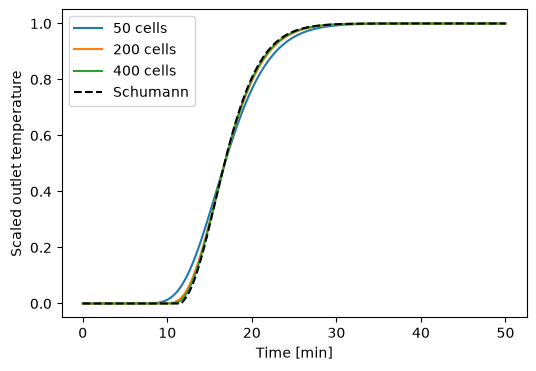

In [2]:
fluid = base.submodels["fluid"]
storage = EnthalpyStorage(param, SensibleMaterial("Capsule"), geometry, label="Capsule")
sensible = pytes.ComposedModel(
    {
        "fluid": fluid,
        "storage": storage,
        "coupling": LedgerWallCoupling(param, param.fluid, "Capsule", geometry),
        "device energy": DeviceEnergy(param, fluid, [storage]),
    },
    param,
    name="Sensible packed bed",
    defaults_from=base,
)
pv = base.default_parameter_values
pv.update(
    {
        "Capsule conductivity [W.m-1.K-1]": 1e3,
        "Capsule density [kg.m-3]": 1000,
        "Capsule specific heat capacity [J.kg-1.K-1]": 2000,
        "Heat transfer coefficient [W.m-2.K-1]": 300,
    },
    check_already_exists=False,
)
h, R, eps = 300, pv["Capsule radius [m]"], pv["Bed porosity"]
Z, A = pv["Bed length [m]"], pv["Bed cross-sectional area [m2]"]
rho_f = pv["Heat transfer fluid density [kg.m-3]"]
c_f = pv["Heat transfer fluid specific heat capacity [J.kg-1.K-1]"]
a = 3 * (1 - eps) / R
u = pv["Mass flow rate [kg.s-1]"] / (rho_f * eps * A)
xi = h * a * Z / (eps * rho_f * c_f * u)
rate = h * a / ((1 - eps) * 1000 * 2000)

t = np.linspace(0, 3000, 151)
exact = [validation.schumann(xi, rate * (ti - Z / u))[0] for ti in t]
fig, ax = plt.subplots(figsize=(6, 4))
for n_z in (50, 200, 400):
    solution = pybamm.Simulation(
        sensible, parameter_values=pv, var_pts={base.r: 5, base.z: n_z}
    ).solve([0, t[-1]], t_interp=t)
    theta = (solution["Outlet temperature [K]"].entries - 305.15) / 38
    ax.plot(t / 60, theta, label=f"{n_z} cells")
ax.plot(t / 60, exact, "k--", label="Schumann")
ax.set_xlabel("Time [min]")
ax.set_ylabel("Scaled outlet temperature")
ax.legend()
plt.show()

The model converges to Schumann's solution at first order in the cell size, as expected
of first-order upwinding: the remaining difference is numerical diffusion.

## Spherical Stefan: a melting capsule

One capsule, solid at its melting temperature, with its surface held 1 K above it (Stefan
number 0.011), against the quasi-steady solution, exact as the Stefan number tends to 0.

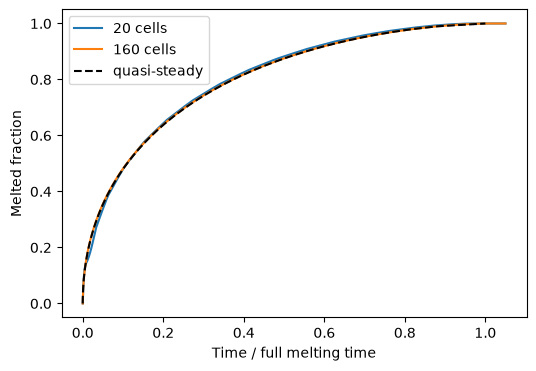

In [3]:
class SurfaceAt(BaseSubModel):
    """Holds the PCM surface at a temperature, and sets the initial temperature"""

    def __init__(self, param, T_surface):
        self.T_surface = T_surface
        super().__init__(param, "Surface")

    def build(self):
        self.variables = {
            "Phase-change material boundary temperature [K]": pybamm.PrimaryBroadcast(
                self.T_surface, "flow path"
            ),
            INITIAL_TEMPERATURE: self.param.T_init,
        }


capsule = EnthalpyStorage(param, param.pcm, geometry, inner_condition="temperature")
melting = pytes.ComposedModel(
    {"storage": capsule, "surface": SurfaceAt(param, param.T_m + 1)},
    param,
    name="Melting capsule",
    defaults_from=base,
)
pv = base.default_parameter_values
pv["PCM smoothing width [K]"] = 0
pv["Initial temperature [K]"] = pv["PCM melting temperature [K]"]
tau = 861 * 213e3 * R**2 / (6 * 0.15 * 1)
t = np.linspace(0, 1.05 * tau, 2001)
fig, ax = plt.subplots(figsize=(6, 4))
for n_r in (20, 160):
    solution = pybamm.Simulation(
        melting, parameter_values=pv, var_pts={base.r: n_r, base.z: 1}
    ).solve([0, t[-1]], t_interp=t)
    ax.plot(t / tau, solution["Average liquid fraction"].entries, label=f"{n_r} cells")
melted = np.linspace(0, 1, 101)
ax.plot(validation.sphere_melting_time(melted), melted, "k--", label="quasi-steady")
ax.set_xlabel("Time / full melting time")
ax.set_ylabel("Melted fraction")
ax.legend()
plt.show()

Both meshes follow the quasi-steady solution. Early on, a coarse mesh deviates slightly:
the melting front crosses the large outer cells of the sphere one at a time (the enthalpy
method with a sharp melting point). Refined, the model is within 1 % of the quasi-steady
solution from half melted onwards.